<img src="assets/ECMWF_Core_Logo_RGB.png" width="170" alt="ECMWF logo">

# Day 3 · Polygons — A Bulgarian November
### #30DayMapChallenge 2026 · ERA5-Land open data · Map by Emma Pidduck

> ⚠️ **Just for fun — not an official ECMWF product.** Claude (Anthropic) helped build
> these notebooks. They are **not** official ECMWF notebooks and are **not** supported by
> ECMWF — a personal [#30DayMapChallenge](https://30daymapchallenge.com/) experiment.

For **Day 3 (Polygons)**, Bulgaria's **265 municipalities** (*obshtini*) are the polygons, with the
**28 provinces** (*oblasti*) outlined on top — two administrative levels at once. Two maps: a
**choropleth** of typical November rainfall, and a **bivariate** pairing rainfall with temperature,
so the cold-and-wet southern mountains stand out against the mild-and-dry lowlands.

Built from **ERA5-Land** (~9 km) — fine enough to resolve the orography the 0.25° atmosphere misses.

> ℹ️ **Re-running this one needs a free [Copernicus CDS](https://cds.climate.copernicus.eu) account + API key**
> (ERA5-Land is served from the CDS, not the no-key cloud store the other days use). Setup: [CDS API how-to](https://cds.climate.copernicus.eu/how-to-api).

## Method

- **Polygons:** 265 municipalities from [geoBoundaries](https://www.geoboundaries.org) ADM2 (CC-BY); 28 province outlines from Natural Earth admin-1 overlaid as the thicker line.
- **The field:** **ERA5-Land**, November **1991–2020** climate normal, at 0.1° (~9 km).
  - *Rainfall* — monthly-mean total precipitation × days in November, averaged over 30 years → typical November total (mm).
  - *Temperature* — mean 2 m temperature over the same window (°C).
- **Per municipality:** the ERA5-Land field is sampled (bilinear) at each municipality centroid.
- **Bivariate:** rainfall and temperature each split into **quartiles**; the 4×4 blend gives each municipality a colour (wetter → right, colder → up).
- Rivers (Danube, Iskar, Maritsa, …) and the capital **Sofia ★** for orientation.

## Licence & attribution

**ERA5-Land** is produced by **ECMWF** for the **Copernicus Climate Change Service (C3S)**; municipality
boundaries are **geoBoundaries** (CC-BY 4.0); province outlines and rivers are **Natural Earth** (public domain).

`Contains modified Copernicus Climate Change Service information [1991–2020]`  ·  `© ECMWF`

## Tools

| Tool | Role |
|---|---|
| [`cdsapi`](https://cds.climate.copernicus.eu/how-to-api) | fetch ERA5-Land monthly means from the Copernicus CDS |
| [`xarray`](https://docs.xarray.dev) · [`geopandas`](https://geopandas.org) | climatology + municipality geometry/zonal sampling |
| [`cartopy`](https://scitools.org.uk/cartopy/docs/latest/) · [`shapely`](https://shapely.readthedocs.io) · [`matplotlib`](https://matplotlib.org) | the choropleth + bivariate render |

**Learn more:** [ERA5-Land (CDS)](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-land-monthly-means)  ·  [geoBoundaries](https://www.geoboundaries.org)  ·  [#30DayMapChallenge](https://30daymapchallenge.com/)

### Configuration

In [1]:
import os, urllib.request
YEARS = (1991, 2020)
AREA  = [44.6, 22.0, 41.0, 29.0]              # N, W, S, E (Bulgaria)
EXTENT= [21.8, 29.2, 40.7, 44.6]
NC    = "data/era5land_nov.nc"
GJ    = "data/bgr_adm2.geojson"
INK, MUT, RIV, PROVLINE, AUTHOR = "#1d2230", "#6b7280", "#2c6fb3", "#2d3440", "Emma Pidduck"
os.makedirs("data", exist_ok=True)

## Retrieve — ERA5-Land from CDS + municipalities from geoBoundaries

In [2]:
if not os.path.exists(NC):
    import cdsapi
    cdsapi.Client().retrieve("reanalysis-era5-land-monthly-means", {
        "product_type": ["monthly_averaged_reanalysis"],
        "variable": ["2m_temperature", "total_precipitation"],
        "year": [str(y) for y in range(YEARS[0], YEARS[1] + 1)],
        "month": ["11"], "time": ["00:00"],
        "data_format": "netcdf", "download_format": "unarchived",
        "area": AREA,
    }, NC)
if not os.path.exists(GJ):
    urllib.request.urlretrieve(
        "https://github.com/wmgeolab/geoBoundaries/raw/main/releaseData/gbOpen/BGR/ADM2/geoBoundaries-BGR-ADM2.geojson", GJ)
print("have ERA5-Land + municipalities")

have ERA5-Land + municipalities


## Compute climatology & sample per municipality

In [3]:
import numpy as np, xarray as xr, geopandas as gpd, warnings
warnings.filterwarnings("ignore")
ds = xr.open_dataset(NC)
precip = ds["tp"].mean("valid_time") * 30 * 1000      # mm (Nov monthly rate x days)
temp   = ds["t2m"].mean("valid_time") - 273.15        # °C
gdf = gpd.read_file(GJ).to_crs(4326)
px = xr.DataArray(gdf.geometry.centroid.x.values, dims="p")
py = xr.DataArray(gdf.geometry.centroid.y.values, dims="p")
P = precip.interp(longitude=px, latitude=py).values
T = temp.interp(longitude=px, latitude=py).values
bad = np.isnan(P) | np.isnan(T)
if bad.any():
    P[bad] = precip.interp(longitude=px, latitude=py, method="nearest").values[bad]
    T[bad] = temp.interp(longitude=px, latitude=py, method="nearest").values[bad]
geoms = list(gdf.geometry.values)
print(f"{len(geoms)} municipalities | precip {P.min():.0f}-{P.max():.0f} mm | temp {T.min():.1f}-{T.max():.1f} °C")

265 municipalities | precip 40-94 mm | temp 1.2-10.2 °C


### Shared map furniture (provinces, rivers, Sofia, logo, footer)

In [4]:
import matplotlib.pyplot as plt, matplotlib.patheffects as pe, matplotlib.image as mpimg
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import cartopy.crs as ccrs, cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
from shapely.ops import unary_union
from shapely.geometry import box
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]
union = gdf.unary_union; BGbox = box(EXTENT[0], EXTENT[2], EXTENT[1], EXTENT[3])
pf = shpreader.natural_earth(resolution="10m", category="cultural", name="admin_1_states_provinces")
PROV = [r.geometry for r in shpreader.Reader(pf).records() if r.attributes.get("admin") == "Bulgaria"]
reu = shpreader.natural_earth(resolution="10m", category="physical", name="rivers_europe")
RIVERS = [g.intersection(union.buffer(0.02)) for r in shpreader.Reader(reu).records() if (g := r.geometry) is not None and g.intersects(union)]
rb = shpreader.natural_earth(resolution="10m", category="physical", name="rivers_lake_centerlines")
DANUBE = [r.geometry.intersection(BGbox) for r in shpreader.Reader(rb).records() if r.attributes.get("name") == "Danube" and r.geometry and r.geometry.intersects(BGbox)]
proj = ccrs.AlbersEqualArea(central_longitude=25.3, central_latitude=42.7, standard_parallels=(41, 44))
halo = [pe.withStroke(linewidth=1.8, foreground="white")]

def furniture(ax):
    ax.set_extent(EXTENT, crs=ccrs.PlateCarree()); ax.set_facecolor("#eef3f6")
    ax.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor="#dbe7ef", zorder=0)
    for g in PROV: ax.add_geometries([g], crs=ccrs.PlateCarree(), facecolor="none", edgecolor=PROVLINE, linewidth=1.3, zorder=4)
    for g in RIVERS: ax.add_geometries([g], crs=ccrs.PlateCarree(), facecolor="none", edgecolor=RIV, linewidth=0.7, alpha=0.8, zorder=5)
    for g in DANUBE: ax.add_geometries([g], crs=ccrs.PlateCarree(), facecolor="none", edgecolor=RIV, linewidth=1.5, alpha=0.85, zorder=5)
    ax.plot(23.3219, 42.6977, marker="*", ms=17, mfc="#ffd23d", mec=INK, mew=1.0, transform=ccrs.PlateCarree(), zorder=8)
    ax.text(23.3219, 42.54, "Sofia", transform=ccrs.PlateCarree(), ha="center", va="top", fontsize=9.5, fontweight="bold", color=INK, zorder=8, path_effects=halo)
    ax.text(28.45, 42.95, "Black\nSea", transform=ccrs.PlateCarree(), ha="center", va="center", fontsize=9.5, style="italic", color="#5b7c91", zorder=3)

def add_logo(fig):
    p = "assets/ECMWF_Core_Logo_RGB.png"
    if os.path.exists(p):
        im = mpimg.imread(p); ar = im.shape[1] / im.shape[0]; h = 0.055; w = h * ar * (fig.get_figheight() / fig.get_figwidth())
        a = fig.add_axes([0.93 - w, 0.02, w, h]); a.imshow(im); a.axis("off")

def add_footer(fig):
    fig.text(0.03, 0.052, "Data: ERA5-Land (ECMWF) · Contains modified Copernicus Climate Change Service information (1991–2020) · boundaries: geoBoundaries + Natural Earth", color=MUT, fontsize=8.3)
    fig.text(0.03, 0.032, "© ECMWF / Copernicus · Map: " + AUTHOR + " · #30DayMapChallenge 2026 · Day 3 · Polygons", color=MUT, fontsize=8.8)

## Map 1 — the choropleth: typical November rainfall

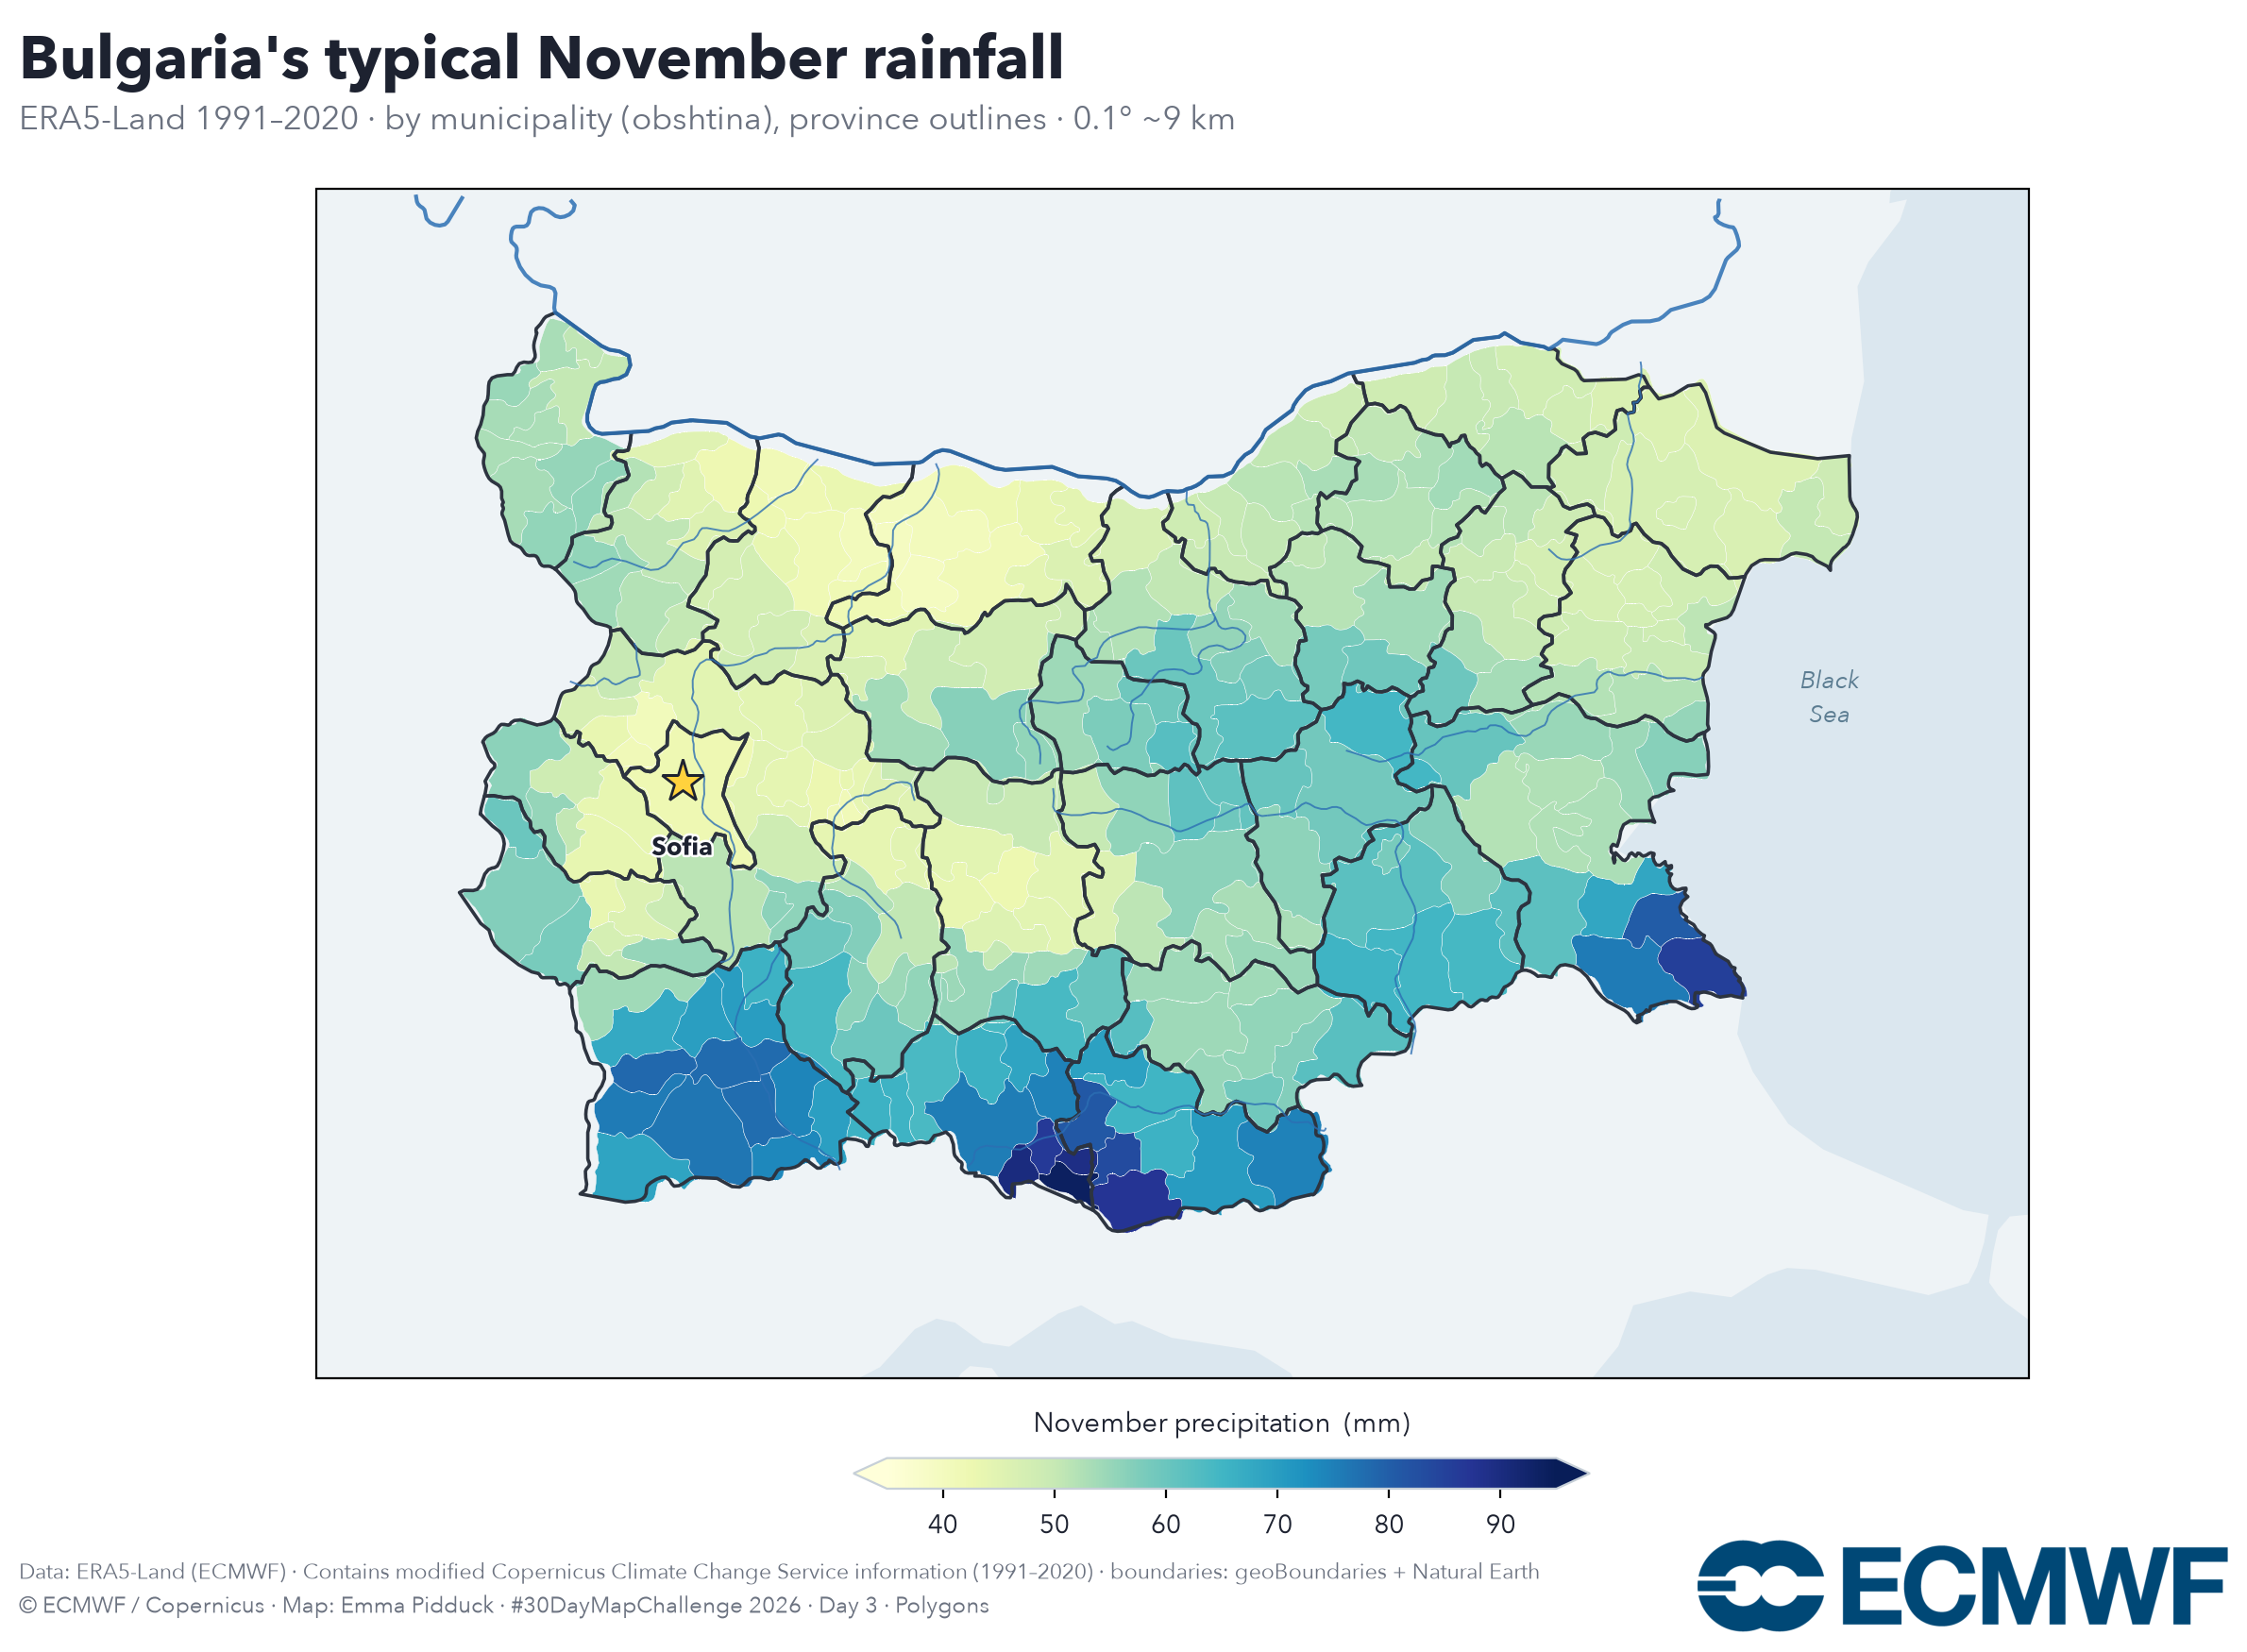

In [5]:
vmin, vmax = np.floor(P.min()/5)*5, np.ceil(P.max()/5)*5
norm = Normalize(vmin, vmax); cmap = plt.get_cmap("YlGnBu")
fig = plt.figure(figsize=(13, 9.0), dpi=200); fig.patch.set_facecolor("#fff")
ax = fig.add_axes([0.03, 0.17, 0.94, 0.70], projection=proj)
for g, v in zip(geoms, P): ax.add_geometries([g], crs=ccrs.PlateCarree(), facecolor=cmap(norm(v)), edgecolor="#ffffff", linewidth=0.15, zorder=2)
furniture(ax)
fig.text(0.03, 0.935, "Bulgaria's typical November rainfall", color=INK, fontsize=23, fontweight="bold")
fig.text(0.03, 0.905, "ERA5-Land 1991–2020 · by municipality (obshtina), province outlines · 0.1° ~9 km", color=MUT, fontsize=12.5)
cax = fig.add_axes([0.37, 0.105, 0.30, 0.018])
cb = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal", extend="both")
cb.set_label("November precipitation  (mm)", color=INK, fontsize=10.5, labelpad=10); cb.ax.xaxis.set_label_position("top")
plt.setp(plt.getp(cb.ax, "xticklabels"), color=INK); cb.outline.set_edgecolor("#c7d0d8")
add_footer(fig); add_logo(fig)
fig.savefig("day03_polygons_rain.png", facecolor="#fff", bbox_inches="tight"); plt.show()

## Map 2 — the bivariate: rainfall × temperature (4×4)

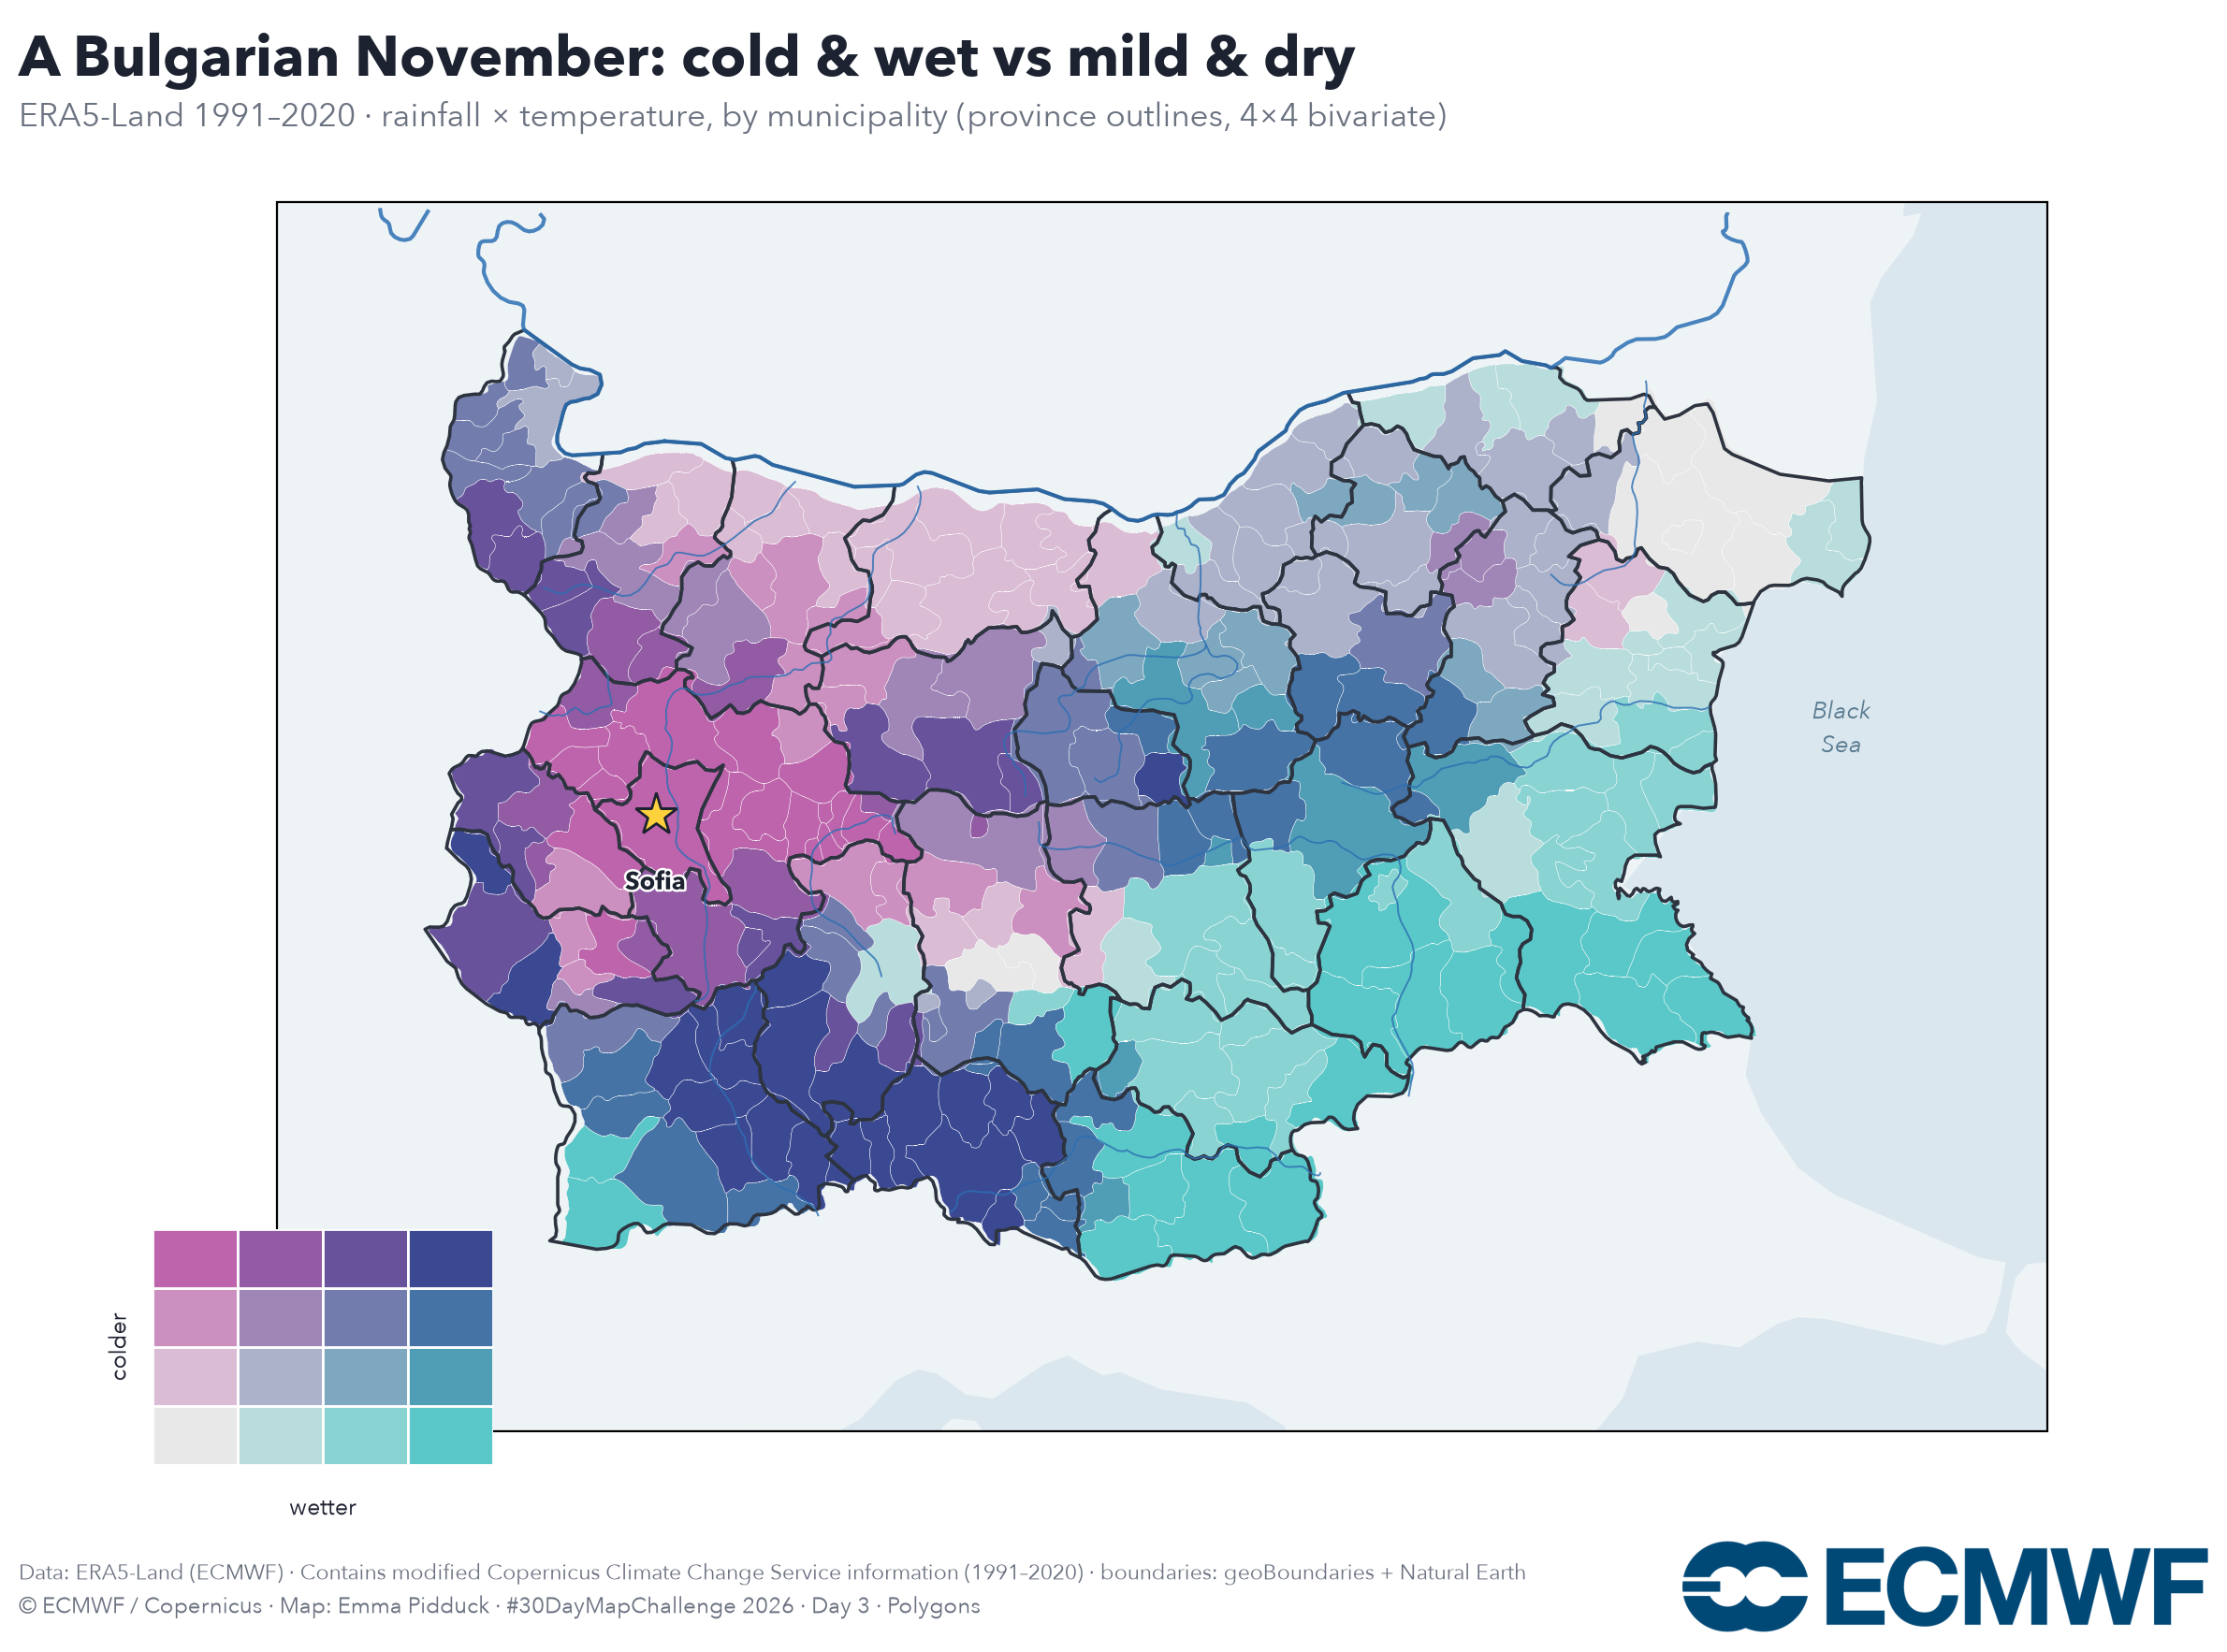

In [6]:
def bil(fx, fy):
    c = np.array([[0.909,0.909,0.909],[0.353,0.784,0.784],[0.745,0.392,0.675],[0.231,0.286,0.576]])
    top = c[0]*(1-fx) + c[1]*fx; bot = c[2]*(1-fx) + c[3]*fx
    return tuple(top*(1-fy) + bot*fy)

N = 4
pcut = np.quantile(P, [k/N for k in range(1, N)]); tcut = np.quantile(-T, [k/N for k in range(1, N)])
pi = np.digitize(P, pcut); ti = np.digitize(-T, tcut)
fig = plt.figure(figsize=(13, 9.0), dpi=200); fig.patch.set_facecolor("#fff")
ax = fig.add_axes([0.03, 0.14, 0.94, 0.73], projection=proj)
for k, g in enumerate(geoms): ax.add_geometries([g], crs=ccrs.PlateCarree(), facecolor=bil(pi[k]/(N-1), ti[k]/(N-1)), edgecolor="#ffffff", linewidth=0.15, zorder=2)
furniture(ax)
fig.text(0.03, 0.945, "A Bulgarian November: cold & wet vs mild & dry", color=INK, fontsize=22, fontweight="bold")
fig.text(0.03, 0.915, "ERA5-Land 1991–2020 · rainfall × temperature, by municipality (province outlines, 4×4 bivariate)", color=MUT, fontsize=12.5)
sz = 0.035; lax = fig.add_axes([0.085, 0.12, sz*N, sz*N]); lax.set_xlim(0, N); lax.set_ylim(0, N); lax.axis("off")
for i in range(N):
    for j in range(N): lax.add_patch(plt.Rectangle((i, j), 1, 1, facecolor=bil(i/(N-1), j/(N-1)), edgecolor="white", linewidth=1.0))
lax.annotate("", xy=(N+0.15, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=INK, lw=1.3))
lax.annotate("", xy=(0, N+0.15), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=INK, lw=1.3))
lax.text(N/2, -0.45, "wetter", ha="center", va="top", fontsize=9, color=INK)
lax.text(-0.4, N/2, "colder", ha="center", va="center", rotation=90, fontsize=9, color=INK)
add_footer(fig); add_logo(fig)
fig.savefig("day03_polygons_bivariate.png", facecolor="#fff", bbox_inches="tight"); plt.show()

## Note

ERA5-Land (0.1°) resolves the orography the 0.25° atmospheric ERA5 smooths away — the wet southern
mountains and the dry Sofia basin are far sharper per municipality. Figures saved as
`day03_polygons_rain.png` and `day03_polygons_bivariate.png`.

*Part of a #30DayMapChallenge 2026 series built on ECMWF (and Copernicus) open data. Finer-resolution municipality view suggested by Ivan Tsonevsky.*